task2: Time Series Analysis

In [1]:
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

df=pd.read_csv("cleaned_stock_prices_dataset.csv")
display(df)


,symbol,date,open,high,low,close,volume
0,AAL,2014-01-02,25.0700,25.8200,25.0600,25.3600,8998943
1,AAPL,2014-01-02,79.3828,79.5756,78.8601,79.0185,58791957
2,AAP,2014-01-02,110.3600,111.8800,109.2900,109.7400,542711
3,ABBV,2014-01-02,52.1200,52.3300,51.5200,51.9800,4569061
4,ABC,2014-01-02,70.1100,70.2300,69.4800,69.8900,1148391
...,...,...,...,...,...,...,...
497456,XYL,2017-12-29,68.5300,68.8000,67.9200,68.2000,1046677
497457,YUM,2017-12-29,82.6400,82.7100,81.5900,81.6100,1347613
497458,ZBH,2017-12-29,121.7500,121.9500,120.6200,120.6700,1023624
497459,ZION,2017-12-29,51.2800,51.5500,50.8100,50.8300,1261916


In [5]:
#time serie action choice
s = df[df["symbol"]=="AAPL"].sort_values("date").set_index("date")["close"]
print(s.shape)
print(s.isna().sum())
print(s.index.min(),s.index.max())

(1007,)
0
2014-01-02 2017-12-29


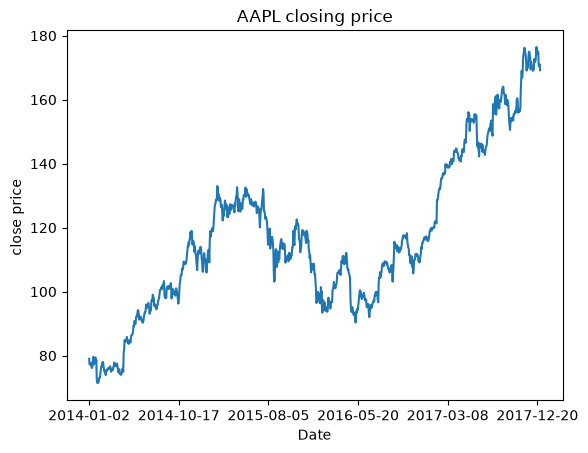

In [6]:
#visualisation this serie
s.plot(title="AAPL closing price")
plt.xlabel("Date")
plt.ylabel("close price ")
plt.show()

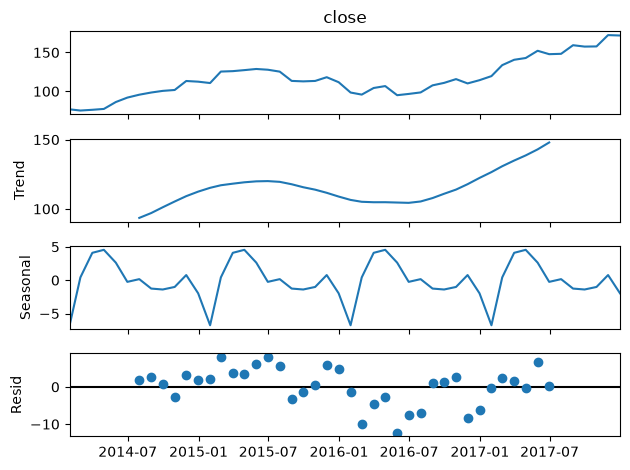

In [11]:
#serie decomposition (trend,seasonnality and residuals)

s.index = pd.to_datetime(s.index)
months = s.resample("ME").mean()
serie=seasonal_decompose(months,model="additive",period=12)
serie.plot()
plt.show()
